<a href="https://colab.research.google.com/github/Jennyaorozco/online-shoppers-intention/blob/main/Desarrollo_proyecto_Online_Shoppers_Intention.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Importación del dataset

Existen dos alternativas para importar el conjunto de datos (dataset). La primera consiste en utilizar la librería ucimlrepo, aunque este método puede presentar inconvenientes en entornos locales debido a errores en la validación de los certificados SSL. La segunda opción es realizar la descarga mediante wget. En el notebook hay celdas que deben ejecutarse únicamente cuando se utiliza un método de importación determinado. Por esta razón, es importante leer atentamente las indicaciones que aparecen en los textos para identificar cuáles celdas corresponden a cada alternativa.

## Importación de dataset usando ucimlrepo

In [ ]:
!pip install ucimlrepo

In [ ]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo

In [ ]:

# fetch dataset
online_shoppers_purchasing_intention_dataset = fetch_ucirepo(id=468)

# data (as pandas dataframes)
X = online_shoppers_purchasing_intention_dataset.data.features
y = online_shoppers_purchasing_intention_dataset.data.targets.copy()

online_shoppers_purchasing_intention_dataset['variables']

,name,role,type,demographic,description,units,missing_values
0,Administrative,Feature,Integer,None,None,None,no
1,Administrative_Duration,Feature,Integer,None,None,None,no
2,Informational,Feature,Integer,None,None,None,no
3,Informational_Duration,Feature,Integer,None,None,None,no
4,ProductRelated,Feature,Integer,None,None,None,no
5,ProductRelated_Duration,Feature,Continuous,None,None,None,no
6,BounceRates,Feature,Continuous,None,None,None,no
7,ExitRates,Feature,Continuous,None,None,None,no
8,PageValues,Feature,Integer,None,None,None,no
9,SpecialDay,Feature,Integer,None,None,None,no


## Importación del dataset usando wget

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
!wget https://github.com/Jennyaorozco/online-shoppers-intention/blob/main/online_shoppers.csv

--2026-10-29 00:08:26--  https://github.com/Jennyaorozco/online-shoppers-intention/blob/main/online_shoppers.csv
Resolving github.com (github.com)... 140.82.114.4
Connecting to github.com (github.com)|140.82.114.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: unspecified [text/html]
Saving to: ‘online_shoppers.csv’

online_shoppers.csv     [ <=>                ] 172.11K   978KB/s    in 0.2s    

2026-10-29 00:08:27 (978 KB/s) - ‘online_shoppers.csv’ saved [176238]



In [ ]:
import pandas as pd

# Descargar el archivo CSV en su formato crudo (raw) para evitar descargar el HTML de GitHub
raw_url = "https://raw.githubusercontent.com/Jennyaorozco/online-shoppers-intention/main/online_shoppers.csv"
df = pd.read_csv(raw_url)

# separar variables predictoras y variable objetivo
X = df.drop(columns=["Revenue"])
y = df[["Revenue"]].copy()

## Análisis variables

De acuerdo a la descripción del dataset disponible en UC Irvine, se concluye que las siguientes variables son categóricas.

- Revenue
- Weekend
- VisitorType
- TrafficType
- Region
- Browser
- OperatingSystems
- Month

In [ ]:
vars_cat = ["Weekend","VisitorType","TrafficType","Region","Browser","OperatingSystems","Month"]
print("Revenue: ",np.unique(y["Revenue"]))
for i in vars_cat:
    print(i+": ", np.unique(X[i]))

Revenue:  [False  True]
Weekend:  [False  True]
VisitorType:  ['New_Visitor' 'Other' 'Returning_Visitor']
TrafficType:  [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20]
Region:  [1 2 3 4 5 6 7 8 9]
Browser:  [ 1  2  3  4  5  6  7  8  9 10 11 12 13]
OperatingSystems:  [1 2 3 4 5 6 7 8]
Month:  ['Aug' 'Dec' 'Feb' 'Jul' 'Jun' 'Mar' 'May' 'Nov' 'Oct' 'Sep']


## Descripción de las variables numéricas

In [ ]:
num_cols = ['Administrative','Administrative_Duration','Informational',
            'Informational_Duration','ProductRelated','ProductRelated_Duration',
            'BounceRates','ExitRates','PageValues','SpecialDay']

In [ ]:
for i in num_cols:
    print(i+": ", X[i].dtype)

Administrative:  float64
Administrative_Duration:  float64
Informational:  float64
Informational_Duration:  float64
ProductRelated:  float64
ProductRelated_Duration:  float64
BounceRates:  float64
ExitRates:  float64
PageValues:  float64
SpecialDay:  float64


In [ ]:
X[num_cols].describe()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.369992,188.295315,0.438200,18.153253,12.999838,1304.336973,0.272132,0.218265,7.626409,0.084185
std,2.828056,366.430474,0.783344,49.295026,7.759546,1760.549049,0.175148,0.147070,16.504281,0.234057
min,0.000000,0.000000,0.000000,0.000000,1.000000,0.189142,0.000437,0.000000,0.000560,0.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,266.327440,0.130908,0.103398,1.039758,0.000000
50%,1.000000,57.649088,0.000000,0.000000,11.000000,716.235937,0.243016,0.197075,2.595851,0.000000
75%,3.000000,210.554445,1.000000,9.994393,17.000000,1659.781555,0.386561,0.313204,6.002672,0.000000
max,26.000000,7706.622831,8.000000,745.467870,57.000000,28616.053986,0.912550,0.774382,264.335041,1.000000


## Preparación encoding variables

### One-hot Encoding

In [ ]:
X = pd.get_dummies(X, columns=['OperatingSystems'], prefix="OperatingSytem_", dtype=int)
X = pd.get_dummies(X, columns=['Browser'], prefix="Browser_", dtype=int)
X = pd.get_dummies(X, columns=['Region'], prefix="Region_", dtype=int)
X = pd.get_dummies(X, columns=['TrafficType'], prefix="TrafficType_", dtype=int)
X = pd.get_dummies(X, columns=['VisitorType'], prefix="VisitorType_", dtype=int)

### Label Encoding si se importo el dataset usando wget

In [ ]:
X['Month'] = X['Month'].map({
    'Feb': 1,
    'Mar': 2,
    'May': 3,
    'Jun': 4,
    'Jul': 5,
    'Aug': 6,
    'Sep': 7,
    'Oct': 8,
    'Nov': 9,
    'Dec': 10
})

### Label Encoding si se importo el dataset usando ucimlrepo

In [ ]:
X['Month'] = X['Month'].map({
    'Feb': 1,
    'Mar': 2,
    'May': 3,
    'June': 4,
    'Jul': 5,
    'Aug': 6,
    'Sep': 7,
    'Oct': 8,
    'Nov': 9,
    'Dec': 10
})

### Convertir valores tipos Boolean a int(0 y 1)

In [ ]:
X['Weekend'] = X['Weekend'].astype(int)

In [ ]:
y['Revenue'] = y['Revenue'].astype(int)

### Nuevos shapes

In [ ]:
X.shape, y.shape


((12330, 65), (12330, 1))

# Separación de test y train, demostración de la aplicación de SMOTE y definición de validación cruzada

### Dividimos el dataset en test y train, asignando un 20% para el test

In [ ]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

# División train/test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

### Aplicación de SMOTE para generar muestras artificiales de la clase minoritaria de manera demostrativa para explorar los efectos de SMOTE

#### Se obtiene la relación entre la clase positiva y la clase negativa

In [ ]:
clase_negativo, clase_positivo = y_train.value_counts()
(clase_positivo)/(clase_negativo)

0.2024868950384006

### Primer porcentaje: Se aumenta la proporción de un 20% a un 22%

In [ ]:
# Aplicar Imputación y SMOTE de forma segura mediante un Pipeline secuencial
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline

pipeline_balanceo_demo = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # Corrige los NaN causados por el mapeo de Month
    ('smote', SMOTE(random_state=42, sampling_strategy=0.22))
])

# Ajustar e imputar/balancear el conjunto de entrenamiento sin romper el flujo
X_train_resampled, y_train_resampled = pipeline_balanceo_demo.fit_resample(
    X_train,
    y_train
)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline

# Definir el pipeline con imputación de nulos (usando la estrategia de la mediana como ejemplo) y SMOTE
pipeline_balanceo = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.22))
])

# Ajustar e imputar/balancear el conjunto de entrenamiento de forma segura
X_train_resampled, y_train_resampled = pipeline_balanceo.fit_resample(X_train, y_train)

# Verificar dimensiones y nulos resultantes
print("Nulos en X_train_resampled:", np.isnan(X_train_resampled).sum().sum())
print("Forma de X_train_resampled:", X_train_resampled.shape)
print("Distribución de clases después de SMOTE:")
print(y_train_resampled.value_counts())

Nulos en X_train_resampled: 0
Forma de X_train_resampled: (10007, 64)
Distribución de clases después de SMOTE:
Revenue
0          8203
1          1804
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
print(y_train.value_counts())
print(y_train_resampled.value_counts())

Revenue
0          8203
1          1661
Name: count, dtype: int64
Revenue
0          8203
1          1804
Name: count, dtype: int64


#### Segundo porcentaje: Se aumenta la proporción de un 20% a un 30%

In [ ]:
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline

# Definir el pipeline secuencial de forma segura
pipeline_balanceo1 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.3))
])

# Ajustar e imputar/balancear el conjunto de entrenamiento sin data leakage
X_train_resampled1, y_train_resampled1 = pipeline_balanceo1.fit_resample(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
print(y_train.value_counts())
print(y_train_resampled1.value_counts())

Revenue
0          8203
1          1661
Name: count, dtype: int64
Revenue
0          8203
1          2460
Name: count, dtype: int64


#### Tercer porcentaje: Se aumenta la proporción de un 20% a un 40%

In [ ]:
# Aplicar Imputación y SMOTE de forma segura mediante un Pipeline secuencial
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

# Definir el pipeline con imputación de nulos y SMOTE al 40%
pipeline_balanceo2 = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # Corrige los NaN causados por el mapeo duplicado de Month
    ('smote', SMOTE(random_state=42, sampling_strategy=0.4))
])

# Ajustar e imputar/balancear el conjunto de entrenamiento sin romper el flujo
X_train_resampled2, y_train_resampled2 = pipeline_balanceo2.fit_resample(
    X_train,
    y_train
)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
print(y_train.value_counts())
print(y_train_resampled2.value_counts())

Revenue
0          8203
1          1661
Name: count, dtype: int64
Revenue
0          8203
1          3281
Name: count, dtype: int64


### Definición de metodología de validación

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

# Entrenamiento de modelos usando pipeline con normalización, SMOTE y malla de hiperparametros

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, learning_curve, cross_val_score

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.svm import SVC

from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score, f1_score

from sklearn.utils.parallel import Parallel, delayed

from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


### Transformación de y train para asegurar su compatibilidad respecto a dimensiones

In [ ]:
y_train = y_train.values.ravel()

### Random Forest

#### Definición de pipeline y malla de hiperparametros

In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import numpy as np

In [ ]:
# PIPELINE  (scaler → SMOTE → RandomForest)
# El StandardScaler no es estrictamente necesario para RF, pero se mantiene para ser consistente con los demás modelos del proyecto y porque SMOTE opera mejor con datos escalados.

pipeline_rf = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.3)),   # valor base; GridSearch lo variará
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1,          # usar todos los núcleos disponibles
        class_weight='balanced'  # refuerzo adicional para clase minoritaria (Revenue=1)
    ))
])


In [ ]:
# Parámetros clave para RF:
#   n_estimators   → número de árboles; más árboles = más estable, más lento
#   max_depth      → profundidad máxima; None = crece hasta hojas puras (riesgo overfitting)
#   min_samples_split → muestras mínimas para dividir un nodo (regularización)
#   min_samples_leaf  → muestras mínimas en hoja (regularización)
#   max_features   → features evaluados en cada split; 'sqrt' es estándar para clasificación
#   sampling_strategy → proporción SMOTE (clase_positiva / clase_negativa)

param_grid_rf = {
    # SMOTE (evaluar los 3 porcentajes)
    'smote__sampling_strategy': [0.22, 0.3, 0.4],
    'smote__k_neighbors': [3, 5, 7],

    # RF — solo los más influyentes, valores fijos para el resto
    'classifier__n_estimators': [200],        # fijo, suficiente para estabilidad
    'classifier__max_depth': [10, 20],        # el más importante a explorar
    'classifier__min_samples_leaf': [1, 4],   # segundo más importante
    'classifier__max_features': ['sqrt'],     # fijo, es el estándar para clasificación
}

In [ ]:
# GRID SEARCH CON VALIDACIÓN CRUZADA ESTRATIFICADA
# Se usa roc_auc (igual que en la evaluación final del proyecto,
# ver: scoring = "roc_auc" y roc_auc_score en la sección de LR)

from sklearn.model_selection import StratifiedKFold

cv_strategy = StratifiedKFold(
    n_splits=10,
    shuffle=True,
    random_state=42
)

grid_rf = GridSearchCV(
    estimator=pipeline_rf,
    param_grid=param_grid_rf,
    cv=cv_strategy,         # StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
    scoring='balanced_accuracy',      # métrica principal del proyecto
    n_jobs=-1,
    verbose=0,
    error_score='raise',
    refit=True              # refitea automáticamente con los mejores parámetros
)

#### Entrenamiento usando la malla de valores y validación cruzada

In [ ]:
from sklearn.impute import SimpleImputer

# Modificamos el pipeline original para incluir imputación y evitar problemas con NaNs
pipeline_rf = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # Corrige los NaN causados por el mapeo de Month
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.3)),
    ('classifier', RandomForestClassifier(
        random_state=42,
        n_jobs=-1,
        class_weight='balanced'
    ))
])

# Actualizamos el estimador en grid_rf con el nuevo pipeline
grid_rf.estimator = pipeline_rf

# Entrenamiento seguro
grid_rf.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('imputer',
                                        SimpleImputer(strategy='median')),
                                       ('scaler', StandardScaler()),
                                       ('smote',
                                        SMOTE(random_state=42,
                                              sampling_strategy=0.3)),
                                       ('classifier',
                                        RandomForestClassifier(class_weight='balanced',
                                                               n_jobs=-1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [10, 20],
                         'classifier__max_features': ['sqrt'],
                         'classifier__min_samples_leaf': [1, 4],
                         'classifier__n_estimators': [200],
                         'smote__k_neighbors': [3, 5, 7],
                         'smote__sampling_strategy': [0.22, 0.3, 0.4]},
             scoring='balanced_accuracy')

#### Resultados de los mejores 3 pipelines

In [ ]:
# OBTENER LOS 3 MEJORES PIPELINES DE LA VALIDACIÓN CRUZADA
from sklearn.impute import SimpleImputer
cv_results = grid_rf.cv_results_
n_top = 3
top_indices = np.argsort(cv_results['mean_test_score'])[-n_top:][::-1]

print("\n" + "=" * 80)
print("TOP 3 PIPELINES SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i, idx in enumerate(top_indices, 1):
    # Obtener hiperparámetros
    params = cv_results['params'][idx]
    balanced_acc_cv_mean = cv_results['mean_test_score'][idx]
    balanced_acc_cv_std = cv_results['std_test_score'][idx]

    # Reconstruir pipeline con estos parámetros e incluir Imputación para evitar errores por NaNs
    pipeline_temp = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'])),
        ('classifier', RandomForestClassifier(
            random_state=42, n_jobs=-1, class_weight='balanced',
            n_estimators=params['classifier__n_estimators'],
            max_depth=params['classifier__max_depth'],
            min_samples_leaf=params['classifier__min_samples_leaf'],
            max_features=params['classifier__max_features']
        ))
    ])

    # Entrenar y evaluar
    pipeline_temp.fit(X_train, y_train)
    y_train_pred = pipeline_temp.predict(X_train)
    y_test_pred = pipeline_temp.predict(X_test)
    y_test_prob = pipeline_temp.predict_proba(X_test)[:, 1]

    # Métricas
    from sklearn.metrics import balanced_accuracy_score, roc_auc_score, f1_score

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE #{i}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV mean): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()


TOP 3 PIPELINES SEGÚN BALANCED_ACCURACY (CV)


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impu


PIPELINE #1
HIPERPARÁMETROS:
  classifier__max_depth: 10
  classifier__max_features: sqrt
  classifier__min_samples_leaf: 4
  classifier__n_estimators: 200
  smote__k_neighbors: 7
  smote__sampling_strategy: 0.3

BALANCED_ACCURACY:
  Train: 0.8649
  Validation (CV mean): 0.8544 (±0.0138)

TEST:
  ROC-AUC: 0.9047
  F1-Score: 0.7562



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



PIPELINE #2
HIPERPARÁMETROS:
  classifier__max_depth: 10
  classifier__max_features: sqrt
  classifier__min_samples_leaf: 4
  classifier__n_estimators: 200
  smote__k_neighbors: 5
  smote__sampling_strategy: 0.4

BALANCED_ACCURACY:
  Train: 0.8672
  Validation (CV mean): 0.8534 (±0.0135)

TEST:
  ROC-AUC: 0.9034
  F1-Score: 0.7585



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



PIPELINE #3
HIPERPARÁMETROS:
  classifier__max_depth: 10
  classifier__max_features: sqrt
  classifier__min_samples_leaf: 1
  classifier__n_estimators: 200
  smote__k_neighbors: 7
  smote__sampling_strategy: 0.3

BALANCED_ACCURACY:
  Train: 0.8696
  Validation (CV mean): 0.8533 (±0.0136)

TEST:
  ROC-AUC: 0.9029
  F1-Score: 0.7619



#### Resultados

In [ ]:
# RESULTADOS DEL GRID SEARCH
print("=" * 60)
print("MEJORES HIPERPARÁMETROS ENCONTRADOS:")
print("=" * 60)
for param, value in grid_rf.best_params_.items():
    print(f"  {param}: {value}")

print(f"\nMejor ROC-AUC (CV en train): {grid_rf.best_score_:.4f}")

MEJORES HIPERPARÁMETROS ENCONTRADOS:
  classifier__max_depth: 10
  classifier__max_features: sqrt
  classifier__min_samples_leaf: 4
  classifier__n_estimators: 200
  smote__k_neighbors: 7
  smote__sampling_strategy: 0.3

Mejor ROC-AUC (CV en train): 0.8544


In [ ]:
# VALIDACIÓN CRUZADA FINAL CON EL MEJOR PIPELINE
scores_rf = cross_val_score(
    grid_rf.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)

print(f"\nROC-AUC por fold (CV):")
print(np.round(scores_rf, 4))
print(f"Media:  {scores_rf.mean():.4f}")
print(f"Std:    {scores_rf.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impu


ROC-AUC por fold (CV):
[0.9339 0.9065 0.9058 0.8984 0.9044 0.9146 0.8713 0.9061 0.9047 0.9065]
Media:  0.9052
Std:    0.0145


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
# EVALUACIÓN FINAL EN TEST
best_rf = grid_rf.best_estimator_
best_rf.fit(X_train, y_train)

y_pred_prob_rf = best_rf.predict_proba(X_test)[:, 1]
y_pred_rf = best_rf.predict(X_test)

roc_auc_test = roc_auc_score(y_test, y_pred_prob_rf)

print("\n" + "=" * 60)
print(f"ROC-AUC EN TEST: {roc_auc_test:.4f}")
print("=" * 60)

print("\nReporte de clasificación (threshold=0.5):")
print(classification_report(y_test, y_pred_rf, target_names=['No compra (0)', 'Compra (1)']))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_rf))


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



ROC-AUC EN TEST: 0.9043

Reporte de clasificación (threshold=0.5):
               precision    recall  f1-score   support

No compra (0)       0.96      0.95      0.95      2051
   Compra (1)       0.75      0.78      0.76       415

     accuracy                           0.92      2466
    macro avg       0.85      0.86      0.86      2466
 weighted avg       0.92      0.92      0.92      2466

Matriz de confusión:
[[1942  109]
 [  91  324]]


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_rf, y_pred_prob_rf)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

ROC-AUC test: 0.9044 (IC 95%: [0.8849, 0.9233])
F1 test:      0.7640 (IC 95%: [0.7319, 0.7953])


#### Curva de Aprendizaje

(0.75, 1.01)

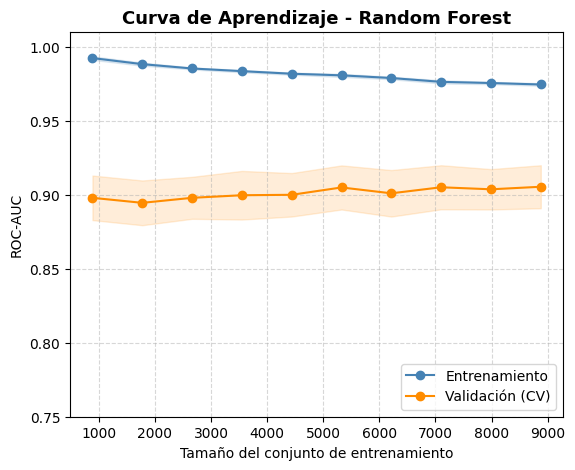

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve

fig = plt.figure(figsize=(14, 5))
gs = gridspec.GridSpec(1, 2, figure=fig)

train_sizes, train_scores, val_scores = learning_curve(
    grid_rf.best_estimator_,
    X_train, y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

ax1 = fig.add_subplot(gs[0])
ax1.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Entrenamiento')
ax1.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='steelblue')
ax1.plot(train_sizes, val_mean, 'o-', color='darkorange', label='Validación (CV)')
ax1.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='darkorange')
ax1.set_title('Curva de Aprendizaje - Random Forest', fontsize=13, fontweight='bold')
ax1.set_xlabel('Tamaño del conjunto de entrenamiento')
ax1.set_ylabel('ROC-AUC')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylim(0.75, 1.01)

#### Matriz de confusión

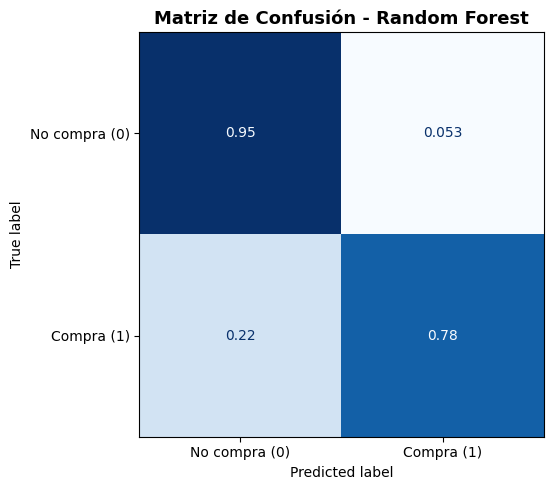

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve

fig = plt.figure(figsize=(14, 5))
gs = gridspec.GridSpec(1, 2, figure=fig)

cm = confusion_matrix(y_test, y_pred_rf,normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No compra (0)', 'Compra (1)'])

ax2 = fig.add_subplot(gs[1])
disp.plot(ax=ax2, colorbar=False, cmap='Blues')
ax2.set_title('Matriz de Confusión - Random Forest', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('rf_curva_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

### XGBoost

In [ ]:
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import numpy as np

In [ ]:
pipeline_xgb = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.3)),
    ('classifier', XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss',   # evita warning interno de XGBoost
        verbosity=0              # silencia logs innecesarios
    ))
])

#### MALLA DE HIPERPARÁMETROS

In [ ]:
param_grid_xgb = {
    # SMOTE — los 3 porcentajes requeridos
    'smote__sampling_strategy': [0.22, 0.3, 0.4],
    'smote__k_neighbors': [3, 5, 7],

    # XGBoost — parámetros más influyentes
    'classifier__n_estimators': [200],
    'classifier__max_depth': [3, 6],          # profundidad del árbol base
    'classifier__learning_rate': [0.05, 0.1], # tasa de aprendizaje
    'classifier__subsample': [0.8],           # fracción de muestras por árbol
    'classifier__colsample_bytree': [0.8],    # fracción de features por árbol
}

#### GRID SEARCH

In [ ]:
grid_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid_xgb,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0,
    refit=True
)

#### Entrenamiento usando la malla de valores y validación cruzada

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from xgboost import XGBClassifier

# 1. Definir el pipeline seguro que incluye la imputación de NaNs
pipeline_xgb = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # Corrige los NaN causados por el mapeo de Month
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, sampling_strategy=0.3)),
    ('classifier', XGBClassifier(
        random_state=42,
        n_jobs=-1,
        eval_metric='logloss',
        verbosity=0
    ))
])

# 2. Definir la malla de parámetros usando la configuración previa
param_grid_xgb = {
    'smote__sampling_strategy': [0.22, 0.3, 0.4],
    'smote__k_neighbors': [3, 5, 7],
    'classifier__n_estimators': [200],
    'classifier__max_depth': [3, 6],
    'classifier__learning_rate': [0.05, 0.1],
    'classifier__subsample': [0.8],
    'classifier__colsample_bytree': [0.8],
}

# 3. Inicializar el GridSearchCV
grid_xgb = GridSearchCV(
    estimator=pipeline_xgb,
    param_grid=param_grid_xgb,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0,
    refit=True
)

# 4. Ajustar el modelo de forma segura
grid_xgb.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('imputer',
                                        SimpleImputer(strategy='median')),
                                       ('scaler', StandardScaler()),
                                       ('smote',
                                        SMOTE(random_state=42,
                                              sampling_strategy=0.3)),
                                       ('classifier',
                                        XGBClassifier(base_score=None,
                                                      booster=None,
                                                      callbacks=None,
                                                      colsample_bylevel=None,
                                                      colsample_bynode=None,
                                                      colsa...
                                                      n_estimators=None,
                                                      n_jobs=-1,
                                                      num_parallel_tree=None, ...))]),
             n_jobs=-1,
             param_grid={'classifier__colsample_bytree': [0.8],
                         'classifier__learning_rate': [0.05, 0.1],
                         'classifier__max_depth': [3, 6],
                         'classifier__n_estimators': [200],
                         'classifier__subsample': [0.8],
                         'smote__k_neighbors': [3, 5, 7],
                         'smote__sampling_strategy': [0.22, 0.3, 0.4]},
             scoring='balanced_accuracy')

#### Resultados de los mejores 3 pipelines

In [ ]:
from sklearn.impute import SimpleImputer

n_top = 3
# OBTENER LOS 3 MEJORES PIPELINES DE XGBOOST
cv_results_xgb = grid_xgb.cv_results_
top_indices_xgb = np.argsort(cv_results_xgb['mean_test_score'])[-n_top:][::-1]

print("\n" + "=" * 80)
print("TOP 3 PIPELINES XGBOOST SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i, idx in enumerate(top_indices_xgb, 1):
    params = cv_results_xgb['params'][idx]
    balanced_acc_cv_mean = cv_results_xgb['mean_test_score'][idx]
    balanced_acc_cv_std = cv_results_xgb['std_test_score'][idx]

    # Reconstruir pipeline con estos parámetros (incluyendo SimpleImputer para resolver los NaNs)
    pipeline_temp_xgb = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'])),
        ('classifier', XGBClassifier(
            random_state=42,
            n_jobs=-1,
            eval_metric='logloss',
            verbosity=0,
            n_estimators=params['classifier__n_estimators'],
            max_depth=params['classifier__max_depth'],
            learning_rate=params['classifier__learning_rate'],
            subsample=params['classifier__subsample'],
            colsample_bytree=params['classifier__colsample_bytree']
        ))
    ])

    # Entrenar y evaluar
    pipeline_temp_xgb.fit(X_train, y_train)
    y_train_pred = pipeline_temp_xgb.predict(X_train)
    y_test_pred = pipeline_temp_xgb.predict(X_test)
    y_test_prob = pipeline_temp_xgb.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE XGBOOST #{i}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV mean): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()


TOP 3 PIPELINES XGBOOST SEGÚN BALANCED_ACCURACY (CV)


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impu


PIPELINE XGBOOST #1
HIPERPARÁMETROS:
  classifier__colsample_bytree: 0.8
  classifier__learning_rate: 0.05
  classifier__max_depth: 3
  classifier__n_estimators: 200
  classifier__subsample: 0.8
  smote__k_neighbors: 3
  smote__sampling_strategy: 0.4

BALANCED_ACCURACY:
  Train: 0.8417
  Validation (CV mean): 0.8314 (±0.0115)

TEST:
  ROC-AUC: 0.9162
  F1-Score: 0.7761



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



PIPELINE XGBOOST #2
HIPERPARÁMETROS:
  classifier__colsample_bytree: 0.8
  classifier__learning_rate: 0.05
  classifier__max_depth: 3
  classifier__n_estimators: 200
  classifier__subsample: 0.8
  smote__k_neighbors: 7
  smote__sampling_strategy: 0.4

BALANCED_ACCURACY:
  Train: 0.8417
  Validation (CV mean): 0.8312 (±0.0103)

TEST:
  ROC-AUC: 0.9162
  F1-Score: 0.7761


PIPELINE XGBOOST #3
HIPERPARÁMETROS:
  classifier__colsample_bytree: 0.8
  classifier__learning_rate: 0.05
  classifier__max_depth: 3
  classifier__n_estimators: 200
  classifier__subsample: 0.8
  smote__k_neighbors: 5
  smote__sampling_strategy: 0.4

BALANCED_ACCURACY:
  Train: 0.8417
  Validation (CV mean): 0.8305 (±0.0114)

TEST:
  ROC-AUC: 0.9162
  F1-Score: 0.7761



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


#### RESULTADOS

In [ ]:
print("=" * 60)
print("MEJORES HIPERPARÁMETROS:")
print("=" * 60)
for param, value in grid_xgb.best_params_.items():
    print(f"  {param}: {value}")

print(f"\nMejor ROC-AUC (CV en train): {grid_xgb.best_score_:.4f}")

MEJORES HIPERPARÁMETROS:
  classifier__colsample_bytree: 0.8
  classifier__learning_rate: 0.05
  classifier__max_depth: 3
  classifier__n_estimators: 200
  classifier__subsample: 0.8
  smote__k_neighbors: 3
  smote__sampling_strategy: 0.4

Mejor ROC-AUC (CV en train): 0.8314


#### EVALUACIÓN FINAL EN TEST


In [ ]:
best_xgb = grid_xgb.best_estimator_
best_xgb.fit(X_train, y_train)

y_pred_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]
y_pred_xgb = best_xgb.predict(X_test)

roc_auc_test = roc_auc_score(y_test, y_pred_prob_xgb)

print("\n" + "=" * 60)
print(f"ROC-AUC EN TEST: {roc_auc_test:.4f}")
print("=" * 60)

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_xgb, target_names=['No compra (0)', 'Compra (1)']))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_xgb))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(



ROC-AUC EN TEST: 0.9169

Reporte de clasificación:
               precision    recall  f1-score   support

No compra (0)       0.94      0.98      0.96      2051
   Compra (1)       0.88      0.70      0.78       415

     accuracy                           0.93      2466
    macro avg       0.91      0.84      0.87      2466
 weighted avg       0.93      0.93      0.93      2466

Matriz de confusión:
[[2013   38]
 [ 125  290]]


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


#### Intervalos de confianza

In [ ]:
from sklearn.model_selection import cross_val_score
scores_xgb = cross_val_score(
    grid_xgb.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)
print(f"ROC-AUC por fold Cross-Validation:")
print(np.round(scores_xgb, 4))
print(f"Media:  {scores_xgb.mean():.4f}")
print(f"Std:    {scores_xgb.std():.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impu

ROC-AUC por fold Cross-Validation:
[0.9295 0.9153 0.9083 0.9111 0.9051 0.9189 0.874  0.9115 0.927  0.9241]
Media:  0.9125
Std:    0.0150


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_xgb, y_pred_prob_xgb)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

ROC-AUC test: 0.9169 (IC 95%: [0.8975, 0.9344])
F1 test:      0.7801 (IC 95%: [0.7461, 0.8120])


#### Curva de Aprendizaje

(0.75, 1.01)

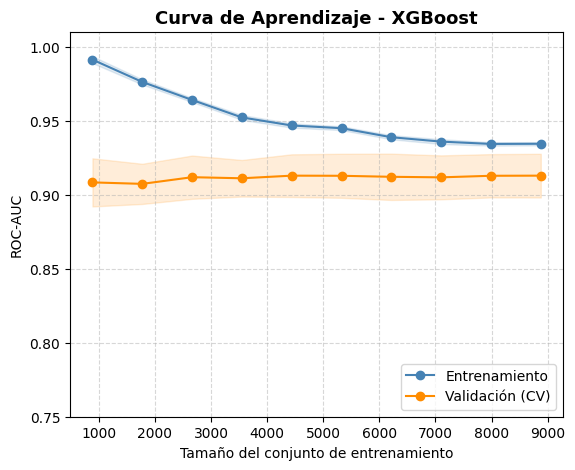

In [56]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve

fig = plt.figure(figsize=(14, 5))
gs = gridspec.GridSpec(1, 2, figure=fig)

train_sizes, train_scores, val_scores = learning_curve(
    grid_xgb.best_estimator_,
    X_train, y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    train_sizes=np.linspace(0.1, 1.0, 10),
    n_jobs=-1
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

ax1 = fig.add_subplot(gs[0])
ax1.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Entrenamiento')
ax1.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='steelblue')
ax1.plot(train_sizes, val_mean, 'o-', color='darkorange', label='Validación (CV)')
ax1.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='darkorange')
ax1.set_title('Curva de Aprendizaje - XGBoost', fontsize=13, fontweight='bold')
ax1.set_xlabel('Tamaño del conjunto de entrenamiento')
ax1.set_ylabel('ROC-AUC')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.set_ylim(0.75, 1.01)

#### MATRIZ DE CONFUSIÓN

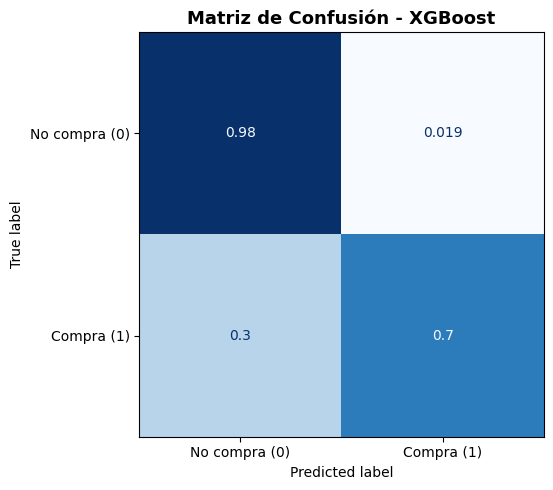


ROC-AUC promedio CV : 0.9128 ± 0.0148
ROC-AUC en test     : 0.9169

Verdaderos Negativos : 0.9814724524622136  |  Falsos Positivos : 0.018527547537786446
Falsos Negativos     : 0.30120481927710846  |  Verdaderos Positivos: 0.6987951807228916


In [57]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import learning_curve

fig = plt.figure(figsize=(14, 5))
gs = gridspec.GridSpec(1, 2, figure=fig)

cm = confusion_matrix(y_test, y_pred_xgb, normalize="true")
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No compra (0)', 'Compra (1)'])

ax2 = fig.add_subplot(gs[1])
disp.plot(ax=ax2, colorbar=False, cmap='Blues')
ax2.set_title('Matriz de Confusión - XGBoost', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.savefig('xgb_curva_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

# ------------------------------------------------------------
# 3. RESUMEN NUMÉRICO
# ------------------------------------------------------------
print(f"\nROC-AUC promedio CV : {val_mean[-1]:.4f} ± {val_std[-1]:.4f}")
print(f"ROC-AUC en test     : {roc_auc_score(y_test, y_pred_prob_xgb):.4f}")
print(f"\nVerdaderos Negativos : {cm[0,0]}  |  Falsos Positivos : {cm[0,1]}")
print(f"Falsos Negativos     : {cm[1,0]}  |  Verdaderos Positivos: {cm[1,1]}")

### MLP

In [58]:
pipeline_mlp = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', MLPClassifier(
        max_iter=1000,
        random_state=42
    ))
])

In [59]:
param_grid_mlp = {

    'smote__sampling_strategy':[0.22,0.3],
    'smote__k_neighbors':[5],

    'classifier__hidden_layer_sizes':[
        (50,),
        (100,)
    ],

    'classifier__activation':[
        'relu'
    ],

    'classifier__alpha':[
        0.0001,
        0.001
    ],

    'classifier__learning_rate_init':[
        0.001,
        0.01
    ]
}

In [60]:
grid_mlp = GridSearchCV(
    estimator=pipeline_mlp,
    param_grid=param_grid_mlp,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0
)

In [61]:
from sklearn.impute import SimpleImputer
from imblearn.pipeline import Pipeline

# Redefinimos el pipeline de MLP para incluir imputación y evitar problemas con NaNs
pipeline_mlp = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),  # Corrige los NaN causados por el mapeo de Month
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', MLPClassifier(
        max_iter=1000,
        random_state=42
    ))
])

# Actualizamos el estimador en grid_mlp
grid_mlp.estimator = pipeline_mlp

# Ajustar el modelo de forma segura
grid_mlp.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


GridSearchCV(cv=StratifiedKFold(n_splits=10, random_state=42, shuffle=True),
             estimator=Pipeline(steps=[('imputer',
                                        SimpleImputer(strategy='median')),
                                       ('scaler', StandardScaler()),
                                       ('smote', SMOTE(random_state=42)),
                                       ('classifier',
                                        MLPClassifier(max_iter=1000,
                                                      random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__activation': ['relu'],
                         'classifier__alpha': [0.0001, 0.001],
                         'classifier__hidden_layer_sizes': [(50,), (100,)],
                         'classifier__learning_rate_init': [0.001, 0.01],
                         'smote__k_neighbors': [5],
                         'smote__sampling_strategy': [0.22, 0.3]},
             scoring='balanced_accuracy')

#### Resultados de los 3 mejores pipelines

In [ ]:
# OBTENER LOS 3 MEJORES PIPELINES DE MLP INCLUYENDO IMPUTADOR
from sklearn.impute import SimpleImputer
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, f1_score
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import numpy as np

# Asegurar existencia y ajuste del grid_mlp en caso de pérdida de estado del kernel
if 'grid_mlp' not in globals() or not hasattr(grid_mlp, 'cv_results_'):
    print("Re-entrenando grid_mlp para recuperar el estado...")
    pipeline_mlp = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', MLPClassifier(max_iter=1000, random_state=42))
    ])
    param_grid_mlp = {
        'smote__sampling_strategy': [0.22, 0.3],
        'smote__k_neighbors': [5],
        'classifier__hidden_layer_sizes': [(50,), (100,)],
        'classifier__activation': ['relu'],
        'classifier__alpha': [0.0001, 0.001],
        'classifier__learning_rate_init': [0.001, 0.01]
    }
    grid_mlp = GridSearchCV(
        estimator=pipeline_mlp,
        param_grid=param_grid_mlp,
        cv=cv_strategy,
        scoring='balanced_accuracy',
        n_jobs=-1,
        verbose=0
    )
    grid_mlp.fit(X_train, y_train)

n_top = 3
cv_results_mlp = grid_mlp.cv_results_
top_indices_mlp = np.argsort(cv_results_mlp['mean_test_score'])[-n_top:][::-1]

print("\n" + "=" * 80)
print("TOP 3 PIPELINES MLP SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i, idx in enumerate(top_indices_mlp, 1):
    params = cv_results_mlp['params'][idx]
    balanced_acc_cv_mean = cv_results_mlp['mean_test_score'][idx]
    balanced_acc_cv_std = cv_results_mlp['std_test_score'][idx]

    # Reconstruir pipeline con estos parámetros e incluir Imputación para evitar errores por NaNs
    pipeline_temp_mlp = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'])),
        ('classifier', MLPClassifier(
            max_iter=1000,
            random_state=42,
            hidden_layer_sizes=params['classifier__hidden_layer_sizes'],
            activation=params['classifier__activation'],
            alpha=params['classifier__alpha'],
            learning_rate_init=params['classifier__learning_rate_init']
        ))
    ])

    # Entrenar y evaluar de forma segura
    pipeline_temp_mlp.fit(X_train, y_train)
    y_train_pred = pipeline_temp_mlp.predict(X_train)
    y_test_pred = pipeline_temp_mlp.predict(X_test)
    y_test_prob = pipeline_temp_mlp.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE MLP #{i}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV mean): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()

#### Mejores hiperparámetros

In [ ]:
grid_mlp.best_score_

In [ ]:
print(grid_mlp.best_params_)

#### Intervalos de confianza del Cross-Validation

In [ ]:
from sklearn.model_selection import cross_val_score, GridSearchCV, StratifiedKFold, train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import pandas as pd
import numpy as np

# 1. Asegurar la existencia de X_train e y_train recreando el flujo si es necesario
if 'X_train' not in globals() or 'y_train' not in globals():
    print("X_train o y_train no definidos. Re-importando y procesando el dataset de forma segura...")
    raw_url = "https://raw.githubusercontent.com/Jennyaorozco/online-shoppers-intention/main/online_shoppers.csv"
    df = pd.read_csv(raw_url)

    X = df.drop(columns=["Revenue"])
    y = df[["Revenue"]].copy()

    # Codificación
    X = pd.get_dummies(X, columns=['OperatingSystems'], prefix="OperatingSytem_", dtype=int)
    X = pd.get_dummies(X, columns=['Browser'], prefix="Browser_", dtype=int)
    X = pd.get_dummies(X, columns=['Region'], prefix="Region_", dtype=int)
    X = pd.get_dummies(X, columns=['TrafficType'], prefix="TrafficType_", dtype=int)
    X = pd.get_dummies(X, columns=['VisitorType'], prefix="VisitorType_", dtype=int)

    X['Month'] = X['Month'].map({
        'Feb': 1, 'Mar': 2, 'May': 3, 'June': 4, 'Jul': 5,
        'Aug': 6, 'Sep': 7, 'Oct': 8, 'Nov': 9, 'Dec': 10
    })
    X['Weekend'] = X['Weekend'].astype(int)
    y['Revenue'] = y['Revenue'].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=42
    )
    y_train = y_train.values.ravel()

# 2. Asegurar que cv_strategy esté definido
if 'cv_strategy' not in globals():
    cv_strategy = StratifiedKFold(
        n_splits=10,
        shuffle=True,
        random_state=42
    )

# 3. Asegurar que grid_mlp esté definido y entrenado
if 'grid_mlp' not in globals() or not hasattr(grid_mlp, 'best_estimator_'):
    print("grid_mlp no estaba definido o entrenado. Entrenando el modelo MLP...")
    pipeline_mlp = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('classifier', MLPClassifier(max_iter=1000, random_state=42))
    ])
    param_grid_mlp = {
        'smote__sampling_strategy': [0.22, 0.3],
        'smote__k_neighbors': [5],
        'classifier__hidden_layer_sizes': [(50,), (100,)],
        'classifier__activation': ['relu'],
        'classifier__alpha': [0.0001, 0.001],
        'classifier__learning_rate_init': [0.001, 0.01]
    }
    grid_mlp = GridSearchCV(
        estimator=pipeline_mlp,
        param_grid=param_grid_mlp,
        cv=cv_strategy,
        scoring='balanced_accuracy',
        n_jobs=-1,
        verbose=0
    )
    grid_mlp.fit(X_train, y_train)

# 4. Realizar la validación cruzada con el mejor estimador de MLP
scores_mlp = cross_val_score(
    grid_mlp.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)

print(f"\nROC-AUC por fold Cross-Validation:")
print(np.round(scores_mlp, 4))
print(f"Media:  {scores_mlp.mean():.4f}")
print(f"Std:    {scores_mlp.std():.4f}")

#### Resultados en test

In [ ]:
best_mlp = grid_mlp.best_estimator_

best_mlp.fit(X_train,y_train)

y_pred_prob_mlp = best_mlp.predict_proba(X_test)[:,1]
y_pred_mlp = best_mlp.predict(X_test)

print("ROC-AUC TEST:")
print(roc_auc_score(y_test,y_pred_prob_mlp))

print(classification_report(y_test,y_pred_mlp))
print(confusion_matrix(y_test,y_pred_mlp))

#### Resultados en train

In [67]:
best_mlp.fit(X_train, y_train)
y_pred_prob_train_mlp = best_mlp.predict_proba(X_train)[:, 1]
y_pred_train_mlp = best_mlp.predict(X_train)
print("ROC-AUC TRAIN:")
print(roc_auc_score(y_train, y_pred_prob_train_mlp))
print(classification_report(y_train, y_pred_train_mlp))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


ROC-AUC TRAIN:
0.9984455254656031
              precision    recall  f1-score   support

           0       1.00      0.98      0.99      8203
           1       0.90      0.99      0.94      1661

    accuracy                           0.98      9864
   macro avg       0.95      0.98      0.96      9864
weighted avg       0.98      0.98      0.98      9864



/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['Month']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_mlp, y_pred_prob_mlp)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

#### Nombres de clases en el classification_report

In [ ]:
print(classification_report(
    y_test, y_pred_mlp,
    target_names=['No compra (0)', 'Compra (1)']
))

#### Matriz de confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# MATRIZ DE CONFUSIÓN NORMALIZADA EN TEST

# predicciones del mejor modelo
y_test_pred = best_mlp.predict(X_test)

# matriz de confusión normalizada
cm = confusion_matrix(
    y_test,
    y_test_pred,
    normalize='true'
)

# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

plt.figure(figsize=(6, 6))

disp.plot(
    cmap='Blues',
    values_format='.2f'
)

plt.title('Matriz de Confusión Normalizada - MLP (Test)')

plt.show()

#### Curva de aprendizaje

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_mlp,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Train ROC_AUC'
)
plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation ROC_AUC'
)
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)
plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)
plt.xlabel('Número de muestras de entrenamiento')
plt.ylabel('ROC_AUC')
plt.title('Curva de Aprendizaje - MLP')
plt.legend()
plt.grid(True)
plt.show()

### K-means


#### Implementación de K-Means como modelo de clasificación mediante asignación por clase mayoritaria

In [ ]:
from sklearn.cluster import KMeans
from sklearn.base import BaseEstimator, ClassifierMixin
import numpy as np

class KMeansClassifier(ClassifierMixin, BaseEstimator):

    _estimator_type = "classifier"

    def __init__(self, n_clusters=2, random_state=42):
        self.n_clusters = n_clusters
        self.random_state = random_state

    def fit(self, X, y):

        y = np.asarray(y).astype(int)

        self.kmeans_ = KMeans(
            n_clusters=self.n_clusters,
            random_state=self.random_state,
            n_init=10
        )

        clusters = self.kmeans_.fit_predict(X)

        self.cluster_labels_ = {}

        for c in np.unique(clusters):

            mask = (clusters == c)

            self.cluster_labels_[c] = np.bincount(
                y[mask]
            ).argmax()

        self.classes_ = np.array([0,1])

        return self

    def predict(self, X):

        clusters = self.kmeans_.predict(X)

        return np.array([
            self.cluster_labels_[c]
            for c in clusters
        ])

    def predict_proba(self, X):
        """Probabilidad basada en distancia inversa al centroide."""
        distances = self.kmeans_.transform(X)  # shape (n, n_clusters)
        # Convertir distancias a scores por clase
        probs = np.zeros((len(X), 2))
        for c in np.unique(list(self.cluster_labels_.values())):
            # Sumar 1/distancia de todos los clusters asignados a esta clase
            for cluster_id, label in self.cluster_labels_.items():
                if label == c:
                    inv_dist = 1.0 / (distances[:, cluster_id] + 1e-8)
                    probs[:, c] += inv_dist
        # Normalizar
        row_sums = probs.sum(axis=1, keepdims=True)
        probs = probs / (row_sums + 1e-8)
        return probs

In [73]:
pipeline_kmeans = Pipeline([

    ('scaler', StandardScaler()),

    ('smote', SMOTE(random_state=42)),

    ('classifier', KMeansClassifier())
])

In [ ]:
param_grid_kmeans = {

    'smote__sampling_strategy': [
        0.22,
        0.3,
        0.4
    ],

    'smote__k_neighbors': [
        3,
        5,
        7
    ],

    'classifier__n_clusters': [
        2,
        3,
        4,
        5
    ]
}

In [ ]:
grid_kmeans = GridSearchCV(
    estimator=pipeline_kmeans,
    param_grid=param_grid_kmeans,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0,
    error_score='raise'
)

In [ ]:
grid_kmeans.fit(X_train,y_train)

#### Resultados para los 3 mejores pipelines

In [ ]:
# OBTENER LOS 3 MEJORES PIPELINES DE KMEANS
cv_results_kmeans = grid_kmeans.cv_results_
top_indices_kmeans = np.argsort(cv_results_kmeans['mean_test_score'])[-3:][::-1]

print("\n" + "=" * 80)
print("TOP 3 PIPELINES KMEANS SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i, idx in enumerate(top_indices_kmeans, 1):
    params = cv_results_kmeans['params'][idx]
    balanced_acc_cv_mean = cv_results_kmeans['mean_test_score'][idx]
    balanced_acc_cv_std = cv_results_kmeans['std_test_score'][idx]

    # Reconstruir pipeline con estos parámetros
    pipeline_temp_kmeans = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'], k_neighbors=params['smote__k_neighbors'])),
        ('classifier', KMeansClassifier(
            n_clusters=params['classifier__n_clusters'],
            random_state=42
        ))
    ])

    # Entrenar y evaluar
    pipeline_temp_kmeans.fit(X_train, y_train)
    y_train_pred = pipeline_temp_kmeans.predict(X_train)
    y_test_pred = pipeline_temp_kmeans.predict(X_test)
    y_test_prob = pipeline_temp_kmeans.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE KMEANS #{i}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()

# MEJOR MODELO KMEANS
print("\n" + "=" * 60)
print("MEJOR MODELO KMEANS (GridSearchCV)")
print("=" * 60)
print(f"Mejor balanced_accuracy (CV): {grid_kmeans.best_score_:.4f}")
print("Mejores hiperparámetros:")
for param, value in grid_kmeans.best_params_.items():
    print(f"  {param}: {value}")

# Evaluación del mejor modelo en test
best_kmeans = grid_kmeans.best_estimator_
y_pred_prob_kmeans = best_kmeans.predict_proba(X_test)[:, 1]
y_pred_kmeans = best_kmeans.predict(X_test)

roc_auc_test = roc_auc_score(y_test, y_pred_prob_kmeans)
print(f"\nROC-AUC en TEST: {roc_auc_test:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_kmeans, target_names=['No compra (0)', 'Compra (1)']))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_kmeans))

#### Mejores hiperparámetros

In [ ]:
grid_kmeans.best_score_

In [ ]:
print(grid_kmeans.best_params_)

#### Intervalos de confianza del Cross-Validation

In [ ]:
scores_kmeans = cross_val_score(
    grid_kmeans.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)
print(f"ROC-AUC por fold Cross-Validation:")
print(np.round(scores_kmeans, 4))
print(f"Media:  {scores_kmeans.mean():.4f}")
print(f"Std:    {scores_kmeans.std():.4f}")

#### Resultados en train

In [ ]:
best_kmeans = grid_kmeans.best_estimator_

best_kmeans.fit(X_train,y_train)

y_pred_prob_kmeans = best_kmeans.predict_proba(X_test)[:,1]
y_pred_kmeans = best_kmeans.predict(X_test)

print("ROC-AUC TEST:")
print(
    roc_auc_score(
        y_test,
        y_pred_prob_kmeans
    )
)

print(
    classification_report(
        y_test,
        y_pred_kmeans
    )
)

print(
    confusion_matrix(
        y_test,
        y_pred_kmeans
    )
)

In [ ]:
y_pred_prob_train_kmeans = best_kmeans.predict_proba(X_train)[:, 1]
y_pred_train_kmeans = best_kmeans.predict(X_train)
print("ROC-AUC TRAIN:")
print(roc_auc_score(y_train, y_pred_prob_train_kmeans))
print(classification_report(y_train, y_pred_train_kmeans,
      target_names=['No compra (0)', 'Compra (1)']))

In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_kmeans, y_pred_prob_kmeans)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

#### Resultados en test

#### Nombres de clases en el classification_report

In [ ]:
print(classification_report(
    y_test,
    y_pred_kmeans,
    target_names=['No compra (0)', 'Compra (1)']
))

#### Matriz de confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# MATRIZ DE CONFUSIÓN NORMALIZADA EN TEST
# predicciones del mejor modelo
y_test_pred = best_kmeans.predict(X_test)
# matriz de confusión normalizada
cm = confusion_matrix(
    y_test,
    y_test_pred,
    normalize='true'
)
# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
plt.figure(figsize=(6, 6))
disp.plot(
    cmap='Blues',
    values_format='.2f'
)
plt.title('Matriz de Confusión Normalizada - K-Means (Test)')
plt.show()

#### Curva de aprendizaje

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_kmeans,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
# medias
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)
plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Train ROC_AUC'
)
plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation ROC_AUC'
)
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)
plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)
plt.xlabel('Número de muestras de entrenamiento')
plt.ylabel('ROC_AUC')
plt.title('Curva de Aprendizaje - K-Means')
plt.legend()
plt.grid(True)
plt.show()

### Regresión lineal

In [ ]:
from sklearn.linear_model import LogisticRegression
from imblearn.pipeline import Pipeline

pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        n_jobs=-1
    ))
])


In [ ]:
param_grid_lr = {
    'smote__sampling_strategy': [0.22, 0.30, 0.40],
    'smote__k_neighbors': [3, 5],
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__penalty': ['l2'],
    'classifier__solver': ['lbfgs']
}

In [ ]:
grid_lr = GridSearchCV(
    estimator=pipeline_lr,
    param_grid=param_grid_lr,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0,
    refit=True
)

#### Entrenamiento

In [ ]:
grid_lr.fit(X_train, y_train)

#### Resultados de los mejores 3 pipelines

In [ ]:
cv_results_lr = grid_lr.cv_results_
top_indices_lr = np.argsort(cv_results_lr['mean_test_score'])[-3:][::-1]

print("\n" + "=" * 80)
print("TOP 3 PIPELINES LOGISTIC REGRESSION SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i, idx in enumerate(top_indices_lr, 1):
    params = cv_results_lr['params'][idx]
    balanced_acc_cv_mean = cv_results_lr['mean_test_score'][idx]
    balanced_acc_cv_std = cv_results_lr['std_test_score'][idx]

    pipeline_temp_lr = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(
            random_state=42,
            sampling_strategy=params['smote__sampling_strategy'],
            k_neighbors=params['smote__k_neighbors']
        )),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42,
            n_jobs=-1,
            C=params['classifier__C'],
            penalty=params['classifier__penalty'],
            solver=params['classifier__solver']
        ))
    ])

    pipeline_temp_lr.fit(X_train, y_train)
    y_train_pred = pipeline_temp_lr.predict(X_train)
    y_test_pred  = pipeline_temp_lr.predict(X_test)
    y_test_prob  = pipeline_temp_lr.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test  = roc_auc_score(y_test, y_test_prob)
    f1_test   = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE LR #{i}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")
    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train:           {balanced_acc_train:.4f}")
    print(f"  Validation (CV): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")
    print(f"\nTEST:")
    print(f"  ROC-AUC:  {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()

#### Resultados

In [ ]:
best_lr = grid_lr.best_estimator_
best_lr.fit(X_train, y_train)

y_pred_prob_lr = best_lr.predict_proba(X_test)[:, 1]
y_pred_lr      = best_lr.predict(X_test)

print("\n" + "=" * 60)
print(f"ROC-AUC EN TEST: {roc_auc_score(y_test, y_pred_prob_lr):.4f}")
print("=" * 60)
print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_lr,
      target_names=['No compra (0)', 'Compra (1)']))

In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_lr, y_pred_prob_lr)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

#### Curva de aprendizaje

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_lr,
    X=X_train, y=y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = train_scores.mean(axis=1)
train_std  = train_scores.std(axis=1)
val_mean   = val_scores.mean(axis=1)
val_std    = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))
plt.plot(train_sizes, train_mean, 'o-', label='Train ROC_AUC')
plt.plot(train_sizes, val_mean,   'o-', label='Validation ROC_AUC')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.2)
plt.fill_between(train_sizes, val_mean - val_std,     val_mean + val_std,     alpha=0.2)
plt.xlabel('Número de muestras de entrenamiento')
plt.ylabel('ROC_AUC')
plt.title('Curva de Aprendizaje - Regresión Logística')
plt.legend()
plt.grid(True)
plt.savefig('lr_curva_aprendizaje.png', dpi=150, bbox_inches='tight')
plt.show()

#### Matriz de confusión

In [ ]:
cm_lr = confusion_matrix(y_test, y_pred_lr, normalize='true')
disp  = ConfusionMatrixDisplay(confusion_matrix=cm_lr,
                                display_labels=['No compra (0)', 'Compra (1)'])
plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='.2f')
plt.title('Matriz de Confusión Normalizada - Regresión Logística (Test)')
plt.savefig('lr_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

### KNN

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

pipeline_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42, k_neighbors=5)),
    ('classifier', KNeighborsClassifier())
])

In [ ]:
param_grid_knn = {
    'smote__sampling_strategy': [0.22, 0.3, 0.4],
    'classifier__n_neighbors': [3, 5, 11],
    'classifier__weights': ['uniform', 'distance'],
    'classifier__metric': ['euclidean', 'manhattan']
}

In [ ]:
grid_knn = GridSearchCV(
    estimator=pipeline_knn,
    param_grid=param_grid_knn,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0
)

In [ ]:
grid_knn.fit(X_train, y_train)

#### Resultados de los 3 mejores pipelines

In [ ]:
# OBTENER LOS 3 MEJORES PIPELINES DE KNN
cv_results_knn = grid_knn.cv_results_
top_indices_knn = np.argsort(cv_results_knn['mean_test_score'])[-3:][::-1]

print("\n" + "=" * 80)
print("TOP 3 PIPELINES KNN SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i, idx in enumerate(top_indices_knn, 1):
    params = cv_results_knn['params'][idx]
    balanced_acc_cv_mean = cv_results_knn['mean_test_score'][idx]
    balanced_acc_cv_std = cv_results_knn['std_test_score'][idx]

    # Reconstruir pipeline con estos parámetros
    pipeline_temp_knn = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42,
                       sampling_strategy=params['smote__sampling_strategy'],
                       k_neighbors=5)),  # k_neighbors fijo para SMOTE
        ('classifier', KNeighborsClassifier(
            n_neighbors=params['classifier__n_neighbors'],
            weights=params['classifier__weights'],
            metric=params['classifier__metric']
        ))
    ])

    # Entrenar y evaluar
    pipeline_temp_knn.fit(X_train, y_train)
    y_train_pred = pipeline_temp_knn.predict(X_train)
    y_test_pred = pipeline_temp_knn.predict(X_test)
    y_test_prob = pipeline_temp_knn.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE KNN #{i}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()

# MEJOR MODELO KNN
print("\n" + "=" * 60)
print("MEJOR MODELO KNN (GridSearchCV)")
print("=" * 60)
print(f"Mejor balanced_accuracy (CV): {grid_knn.best_score_:.4f}")
print("Mejores hiperparámetros:")
for param, value in grid_knn.best_params_.items():
    print(f"  {param}: {value}")

# Evaluación del mejor modelo en test
best_knn = grid_knn.best_estimator_
y_pred_prob_knn = best_knn.predict_proba(X_test)[:, 1]
y_pred_knn = best_knn.predict(X_test)

roc_auc_test = roc_auc_score(y_test, y_pred_prob_knn)
print(f"\nROC-AUC en TEST: {roc_auc_test:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_knn, target_names=['No compra (0)', 'Compra (1)']))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_knn))

#### Mejores hiperparámetros

In [ ]:
grid_knn.best_score_

In [ ]:
print(grid_knn.best_params_)

#### Intervalos de confianza del Cross-Validation

In [ ]:
scores_knn = cross_val_score(
    grid_knn.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)
print(f"ROC-AUC por fold Cross-Validation:")
print(np.round(scores_knn, 4))
print(f"Media:  {scores_knn.mean():.4f}")
print(f"Std:    {scores_knn.std():.4f}")

#### Resultados en train

In [ ]:
best_knn = grid_knn.best_estimator_
best_knn.fit(X_train, y_train)
y_pred_prob_train_knn = best_knn.predict_proba(X_train)[:, 1]
y_pred_train_knn = best_knn.predict(X_train)
print("ROC-AUC TRAIN:")
print(roc_auc_score(y_train, y_pred_prob_train_knn))
print(classification_report(y_train, y_pred_train_knn,
      target_names=['No compra (0)', 'Compra (1)']))

#### Resultados en test

In [ ]:
y_pred_prob_knn = best_knn.predict_proba(X_test)[:, 1]
y_pred_knn = best_knn.predict(X_test)
print("ROC-AUC TEST:")
print(roc_auc_score(y_test, y_pred_prob_knn))
print(classification_report(y_test, y_pred_knn,
      target_names=['No compra (0)', 'Compra (1)']))

In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_knn, y_pred_prob_knn)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

#### Nombres de clases en el classification_report

In [ ]:
print(classification_report(
    y_test,
    y_pred_knn,
    target_names=['No compra (0)', 'Compra (1)']
))

#### Matriz de confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
# MATRIZ DE CONFUSIÓN NORMALIZADA EN TEST
# predicciones del mejor modelo
y_test_pred = best_knn.predict(X_test)
# matriz de confusión normalizada
cm = confusion_matrix(
    y_test,
    y_test_pred,
    normalize='true'
)
# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
plt.figure(figsize=(6, 6))
disp.plot(
    cmap='Blues',
    values_format='.2f'
)
plt.title('Matriz de Confusión Normalizada - KNN (Test)')
plt.show()

#### Curva de aprendizaje

In [ ]:
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_knn,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)
# medias
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)
plt.figure(figsize=(10, 6))
plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Train ROC_AUC'
)
plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation ROC_AUC'
)
plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)
plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)
plt.xlabel('Número de muestras de entrenamiento')
plt.ylabel('ROC_AUC')
plt.title('Curva de Aprendizaje - KNN')
plt.legend()
plt.grid(True)
plt.show()

### SVM

#### Definición de pipeline y malla de hiperparametros

In [ ]:
pipeline_svc = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('svc', SVC(probability=True, random_state=42))
])

In [ ]:
param_grid_svc = [
  {
      'smote__sampling_strategy': [0.22, 0.3],
      'svc__kernel': ['linear'],
      'svc__C': [0.01, 0.1, 1]
  },
  {
      'smote__sampling_strategy': [0.22, 0.3],
      'svc__kernel': ['rbf'],
      'svc__C': [0.01, 0.1, 1],
      'svc__gamma': ['scale', 'auto', 0.01, 0.1],
  }

]

In [ ]:
grid_svc = GridSearchCV(
    estimator=pipeline_svc,
    param_grid=param_grid_svc,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0,
    return_train_score=True
)

#### Entrenamiento usando la malla de hiperparametros

In [ ]:
grid_svc.fit(X_train,y_train)

#### Resultados para los 3 mejores pipelines

In [ ]:
results = pd.DataFrame(grid_svc.cv_results_)

results_sorted = results.sort_values(
    by='mean_test_score',
    ascending=False
).reset_index(drop=True)

In [ ]:
top_3_results = []

for i in range(3):

    row = results_sorted.iloc[i]

    params = row['params']

    # reconstruir pipeline
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('svc', SVC(probability=True, random_state=42))
    ])

    model.set_params(**params)

    # entrenar
    model.fit(X_train, y_train)

    # probabilidades
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # métricas
    train_auc = roc_auc_score(y_train, y_train_proba)
    test_auc = roc_auc_score(y_test, y_test_proba)

    top_3_results.append({
        'rank': i + 1,
        'params': params,
        'train_roc_auc': train_auc,
        'validation_roc_auc': row['mean_test_score'],
        'test_roc_auc': test_auc
    })

In [ ]:
top_3_df = pd.DataFrame(top_3_results)

print("\n===== TOP 3 MODELOS =====\n")
print(top_3_df)

In [ ]:
# OBTENER LOS 3 MEJORES PIPELINES DE SVC
print("\n" + "=" * 80)
print("TOP 3 PIPELINES SVC SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i in range(3):
    row = results_sorted.iloc[i]
    params = row['params']
    balanced_acc_cv_mean = row['mean_test_score']
    balanced_acc_cv_std = row['std_test_score']

    # Reconstruir pipeline según el kernel
    if params['svc__kernel'] == 'linear':
        pipeline_temp_svc = Pipeline([
            ('scaler', StandardScaler()),
            ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'])),
            ('svc', SVC(
                probability=True,
                random_state=42,
                kernel='linear',
                C=params['svc__C']
            ))
        ])
    else:  # rbf
        pipeline_temp_svc = Pipeline([
            ('scaler', StandardScaler()),
            ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'])),
            ('svc', SVC(
                probability=True,
                random_state=42,
                kernel='rbf',
                C=params['svc__C'],
                gamma=params['svc__gamma']
            ))
        ])

    # Entrenar y evaluar
    pipeline_temp_svc.fit(X_train, y_train)
    y_train_pred = pipeline_temp_svc.predict(X_train)
    y_test_pred = pipeline_temp_svc.predict(X_test)
    y_test_prob = pipeline_temp_svc.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE SVC #{i+1}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()

#### Intervalos de confianza

In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_test_pred, y_test_prob)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

In [ ]:
scores_svc = cross_val_score(
    grid_svc.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)
print(f"ROC-AUC por fold Cross-Validation:")
print(np.round(scores_svc, 4))
print(f"Media:  {scores_svc.mean():.4f}")
print(f"Std:    {scores_svc.std():.4f}")

#### Curva de aprendizaje

In [ ]:
best_model = grid_svc.best_estimator_

print("\n===== MEJOR MODELO =====\n")
print(grid_svc.best_params_)
print(f"Best Validation ROC_AUC: {grid_svc.best_score_:.4f}")

train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)

# medias
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Train ROC_AUC'
)

plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation ROC_AUC'
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

plt.xlabel('Número de muestras de entrenamiento')
plt.ylabel('ROC_AUC')
plt.title('Curva de Aprendizaje - Mejor Modelo')
plt.legend()
plt.grid(True)

plt.show()

#### Matriz de confusión

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# =========================================================
# MATRIZ DE CONFUSIÓN NORMALIZADA EN TEST
# =========================================================

# predicciones del mejor modelo
y_test_pred = best_model.predict(X_test)

# matriz de confusión normalizada
cm = confusion_matrix(
    y_test,
    y_test_pred,
    normalize='true'
)

# visualización
disp = ConfusionMatrixDisplay(confusion_matrix=cm)

plt.figure(figsize=(6, 6))

disp.plot(
    cmap='Blues',
    values_format='.2f'
)

plt.title('Matriz de Confusión Normalizada - Test')

plt.show()

### GMM

#### Definición de pipeline y malla de hiperparametros

In [ ]:
import numpy as np

from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.mixture import GaussianMixture
from sklearn.utils.validation import check_X_y, check_array


class GMMClassifier(ClassifierMixin, BaseEstimator):

    def __init__(
        self,
        n_components=1,
        covariance_type='full',
        max_iter=100,
        n_init=1,
        init_params='kmeans',
        random_state=None
    ):
        self.n_components = n_components
        self.covariance_type = covariance_type
        self.max_iter = max_iter
        self.n_init = n_init
        self.init_params = init_params
        self.random_state = random_state

    def __sklearn_tags__(self):

        tags = super().__sklearn_tags__()

        tags.estimator_type = "classifier"

        return tags

    def fit(self, X, y):

        X, y = check_X_y(X, y)

        self.classes_ = np.unique(y)

        self.models_ = {}

        self.priors_ = {}

        for c in self.classes_:

            gmm = GaussianMixture(
                n_components=self.n_components,
                covariance_type=self.covariance_type,
                max_iter=self.max_iter,
                n_init=self.n_init,
                init_params=self.init_params,
                random_state=self.random_state
            )

            X_class = X[y == c]

            gmm.fit(X_class)

            self.models_[c] = gmm

            self.priors_[c] = X_class.shape[0] / X.shape[0]

        return self

    def predict_proba(self, X):

        X = check_array(X)

        log_probs = np.zeros(
            (X.shape[0], len(self.classes_))
        )

        for idx, c in enumerate(self.classes_):

            gmm = self.models_[c]

            log_likelihood = gmm.score_samples(X)

            log_prior = np.log(self.priors_[c])

            log_probs[:, idx] = (
                log_likelihood + log_prior
            )

        log_probs -= log_probs.max(
            axis=1,
            keepdims=True
        )

        probs = np.exp(log_probs)

        probs /= probs.sum(
            axis=1,
            keepdims=True
        )

        return probs

    def predict(self, X):

        probs = self.predict_proba(X)

        return self.classes_[
            np.argmax(probs, axis=1)
        ]

In [ ]:
pipeline_gmm = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('gmm', GMMClassifier(
        random_state=42
    ))
])

In [ ]:
param_grid_gmm = {
    'smote__sampling_strategy': [0.22, 0.3,],
    'gmm__n_components': [1, 2, 3, 4],
    'gmm__covariance_type': ['full', 'diag', 'tied', 'spherical'],
    'gmm__max_iter': [100, 200],
    'gmm__n_init': [1, 2],
    'gmm__init_params': [
        'kmeans',
        'k-means++',
        'random',
        'random_from_data'
    ],
}

In [ ]:
grid_gmm = GridSearchCV(
    estimator=pipeline_gmm,
    param_grid=param_grid_gmm,
    cv=cv_strategy,
    scoring='balanced_accuracy',
    n_jobs=-1,
    verbose=0,
    error_score='raise',
    return_train_score=True
)

#### Entrenamiento usando malla de hiperparametros

In [ ]:
grid_gmm.fit(X_train, y_train)

#### Resultado de los 3 mejores pipelines

#### Resultados

In [ ]:
results = pd.DataFrame(grid_gmm.cv_results_)

results_sorted = results.sort_values(
    by='mean_test_score',
    ascending=False
).reset_index(drop=True)

In [ ]:
top_3_results = []

for i in range(3):

    row = results_sorted.iloc[i]

    params = row['params']

    # reconstruir modelo
    model = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42)),
        ('gmm', GMMClassifier(
            random_state=42
        ))
    ])

    model.set_params(**params)

    # entrenar
    model.fit(X_train, y_train)

    # probabilidades
    y_train_proba = model.predict_proba(X_train)[:, 1]
    y_test_proba = model.predict_proba(X_test)[:, 1]

    # métricas
    train_auc = roc_auc_score(y_train, y_train_proba)
    test_auc = roc_auc_score(y_test, y_test_proba)

    top_3_results.append({
        'rank': i + 1,
        'params': params,
        'train_roc_auc': train_auc,
        'validation_roc_auc': row['mean_test_score'],
        'test_roc_auc': test_auc
    })


In [ ]:
top_3_df = pd.DataFrame(top_3_results)

print("\n===== TOP 3 MODELOS GMM =====\n")
print(top_3_df)

In [ ]:
# OBTENER LOS 3 MEJORES PIPELINES DE GMM (continuación del código existente)
print("\n" + "=" * 80)
print("TOP 3 PIPELINES GMM SEGÚN BALANCED_ACCURACY (CV)")
print("=" * 80)

for i in range(3):
    row = results_sorted.iloc[i]
    params = row['params']
    balanced_acc_cv_mean = row['mean_test_score']
    balanced_acc_cv_std = row['std_test_score']

    # Reconstruir modelo
    pipeline_temp_gmm = Pipeline([
        ('scaler', StandardScaler()),
        ('smote', SMOTE(random_state=42, sampling_strategy=params['smote__sampling_strategy'])),
        ('gmm', GMMClassifier(
            n_components=params['gmm__n_components'],
            covariance_type=params['gmm__covariance_type'],
            max_iter=params['gmm__max_iter'],
            n_init=params['gmm__n_init'],
            init_params=params['gmm__init_params'],
            random_state=42
        ))
    ])

    # Entrenar y evaluar
    pipeline_temp_gmm.fit(X_train, y_train)
    y_train_pred = pipeline_temp_gmm.predict(X_train)
    y_test_pred = pipeline_temp_gmm.predict(X_test)
    y_test_prob = pipeline_temp_gmm.predict_proba(X_test)[:, 1]

    balanced_acc_train = balanced_accuracy_score(y_train, y_train_pred)
    auc_test = roc_auc_score(y_test, y_test_prob)
    f1_test = f1_score(y_test, y_test_pred)

    print(f"\n{'='*80}")
    print(f"PIPELINE GMM #{i+1}")
    print(f"{'='*80}")
    print("HIPERPARÁMETROS:")
    for param, value in params.items():
        print(f"  {param}: {value}")

    print(f"\nBALANCED_ACCURACY:")
    print(f"  Train: {balanced_acc_train:.4f}")
    print(f"  Validation (CV): {balanced_acc_cv_mean:.4f} (±{balanced_acc_cv_std:.4f})")

    print(f"\nTEST:")
    print(f"  ROC-AUC: {auc_test:.4f}")
    print(f"  F1-Score: {f1_test:.4f}")
    print()

# MEJOR MODELO GMM
print("\n" + "=" * 60)
print("MEJOR MODELO GMM (GridSearchCV)")
print("=" * 60)
print(f"Mejor balanced_accuracy (CV): {grid_gmm.best_score_:.4f}")
print("Mejores hiperparámetros:")
for param, value in grid_gmm.best_params_.items():
    print(f"  {param}: {value}")

# Evaluación del mejor modelo en test
best_gmm = grid_gmm.best_estimator_
y_pred_prob_gmm = best_gmm.predict_proba(X_test)[:, 1]
y_pred_gmm = best_gmm.predict(X_test)

roc_auc_test = roc_auc_score(y_test, y_pred_prob_gmm)
print(f"\nROC-AUC en TEST: {roc_auc_test:.4f}")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred_gmm, target_names=['No compra (0)', 'Compra (1)']))

print("Matriz de confusión:")
print(confusion_matrix(y_test, y_pred_gmm))

#### Intervalos de confianza

In [ ]:
# === INTERVALOS DE CONFIANZA BOOTSTRAP para test ===
from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, y_prob, n_bootstrap=1000, alpha=0.05):
    """Calcula IC 95% por bootstrap para ROC-AUC y F1."""
    rng = np.random.RandomState(42)
    aucs, f1s = [], []
    for _ in range(n_bootstrap):
        idx = resample(range(len(y_true)), random_state=rng)
        if len(np.unique(np.array(y_true)[idx])) < 2:
            continue
        aucs.append(roc_auc_score(np.array(y_true)[idx], np.array(y_prob)[idx]))
        f1s.append(f1_score(np.array(y_true)[idx], np.array(y_pred)[idx]))
    lo, hi = alpha/2, 1 - alpha/2
    return {
        'ROC-AUC': (np.percentile(aucs, lo*100), np.mean(aucs), np.percentile(aucs, hi*100)),
        'F1':      (np.percentile(f1s,  lo*100), np.mean(f1s),  np.percentile(f1s,  hi*100))
    }

ci = bootstrap_ci(y_test, y_pred_gmm, y_pred_prob_gmm)
print(f"ROC-AUC test: {ci['ROC-AUC'][1]:.4f} "
      f"(IC 95%: [{ci['ROC-AUC'][0]:.4f}, {ci['ROC-AUC'][2]:.4f}])")
print(f"F1 test:      {ci['F1'][1]:.4f} "
      f"(IC 95%: [{ci['F1'][0]:.4f}, {ci['F1'][2]:.4f}])")

In [ ]:
scores_gmm = cross_val_score(
    grid_gmm.best_estimator_,
    X_train,
    y_train,
    cv=cv_strategy,
    scoring='roc_auc'
)
print(f"ROC-AUC por fold Cross-Validation:")
print(np.round(scores_gmm, 4))
print(f"Media:  {scores_gmm.mean():.4f}")
print(f"Std:    {scores_gmm.std():.4f}")

#### Curva de aprendizaje

In [ ]:
best_model = grid_gmm.best_estimator_

print("\n===== MEJOR MODELO =====\n")
print(grid_gmm.best_params_)
print(f"Best Validation ROC_AUC: {grid_gmm.best_score_:.4f}")

train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    cv=cv_strategy,
    scoring='roc_auc',
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 10)
)

# medias
train_mean = train_scores.mean(axis=1)
train_std = train_scores.std(axis=1)

val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(10, 6))

plt.plot(
    train_sizes,
    train_mean,
    marker='o',
    label='Train ROC_AUC'
)

plt.plot(
    train_sizes,
    val_mean,
    marker='o',
    label='Validation ROC_AUC'
)

plt.fill_between(
    train_sizes,
    train_mean - train_std,
    train_mean + train_std,
    alpha=0.2
)

plt.fill_between(
    train_sizes,
    val_mean - val_std,
    val_mean + val_std,
    alpha=0.2
)

plt.xlabel('Número de muestras de entrenamiento')
plt.ylabel('ROC_AUC')
plt.title('Curva de Aprendizaje - Mejor GMM')
plt.legend()
plt.grid(True)

plt.show()

#### Matriz de confusión

In [ ]:
y_test_pred = best_model.predict(X_test)

cm = confusion_matrix(
    y_test,
    y_test_pred,
    normalize='true'
)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

plt.figure(figsize=(6, 6))

disp.plot(
    cmap='Blues',
    values_format='.2f'
)

plt.title('Matriz de Confusión Normalizada - GMM')

plt.show()

# Reducción de Dimensión

Debe haber ejecutado el notebook principal hasta obtener X_train, X_test, y_train, y_test, best_rf y best_xgb.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
    f1_score, precision_score, recall_score, accuracy_score
)
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

# Instalar UMAP si no está disponible
try:
    import umap
    print("UMAP ya está instalado.")
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "umap-learn", "-q"])
    import umap
    print("UMAP instalado correctamente.")

print("Librerías cargadas correctamente.")

In [ ]:
print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"Variables originales: {X_train.shape[1]}")

## Análisis Individual de Variables

In [ ]:
# ─── Correlación de Pearson (variables numéricas) ───────────────────────────
y_train_flat = np.array(y_train).ravel()
y_series = pd.Series(y_train_flat, name='Revenue')
X_train_df = pd.DataFrame(X_train, columns=X_train.columns if hasattr(X_train, 'columns') else [f'f{i}' for i in range(X_train.shape[1])])

pearson_corr = X_train_df.corrwith(y_series).abs().sort_values(ascending=False)

print("=" * 55)
print("CORRELACIÓN DE PEARSON |r| con Revenue (descendente)")
print("=" * 55)
print(pearson_corr.to_string())

In [ ]:
# ─── Information Value (IV) ──────────────────────────────────────────────────
def compute_iv(X_df, y, n_bins=10):
    """
    Calcula el Information Value para cada variable.
    Variables continuas se discretizan en cuantiles.
    """
    iv_dict = {}
    y = np.array(y)
    total_pos = y.sum()
    total_neg = len(y) - total_pos

    for col in X_df.columns:
        x = X_df[col].values
        n_unique = len(np.unique(x))

        # Discretizar variables continuas en cuantiles
        if n_unique > n_bins:
            try:
                bins = pd.qcut(x, q=n_bins, duplicates='drop', labels=False)
            except Exception:
                bins = pd.cut(x, bins=n_bins, labels=False)
        else:
            bins = x

        iv = 0.0
        for b in np.unique(bins):
            mask = (bins == b)
            n_pos = y[mask].sum()
            n_neg = mask.sum() - n_pos

            dist_pos = (n_pos + 0.5) / (total_pos + 0.5)
            dist_neg = (n_neg + 0.5) / (total_neg + 0.5)
            woe = np.log(dist_pos / dist_neg)
            iv += (dist_pos - dist_neg) * woe

        iv_dict[col] = iv

    return pd.Series(iv_dict).sort_values(ascending=False)


iv_series = compute_iv(X_train_df, y_train)

print("=" * 55)
print("INFORMATION VALUE (IV) por variable (descendente)")
print("=" * 55)
print(iv_series.to_string())
print("\nEscala de referencia IV:")
print("  < 0.02 → nulo/inútil | 0.02–0.1 → débil | 0.1–0.3 → medio | >0.3 → fuerte")

## Tabla de candidatas a eliminación

In [ ]:
summary_df = pd.DataFrame({
    'Pearson_abs': pearson_corr,
    'IV': iv_series
}).dropna()

# Umbral de eliminación
PEARSON_THRESHOLD = 0.05
IV_THRESHOLD = 0.02

summary_df['Candidata_eliminacion'] = (
    (summary_df['Pearson_abs'] < PEARSON_THRESHOLD) &
    (summary_df['IV'] < IV_THRESHOLD)
)

candidatas = summary_df[summary_df['Candidata_eliminacion']].index.tolist()

print("=" * 60)
print("TABLA RESUMEN – Análisis Individual de Variables")
print("=" * 60)
print(summary_df.sort_values('IV', ascending=False).to_string())
print(f"\n>>> Candidatas a eliminación ({len(candidatas)} variables):")
for v in candidatas:
    print(f"    - {v}")

## Visualización: heatmap de correlación (top 20) y barras IV

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Barras – Pearson
top20_pearson = pearson_corr.head(20)
colors_p = ['steelblue' if v >= PEARSON_THRESHOLD else 'salmon' for v in top20_pearson]
axes[0].barh(top20_pearson.index[::-1], top20_pearson.values[::-1], color=colors_p[::-1])
axes[0].axvline(PEARSON_THRESHOLD, color='red', linestyle='--', linewidth=1.5, label=f'Umbral {PEARSON_THRESHOLD}')
axes[0].set_title('Top 20 variables – |Correlación de Pearson|', fontweight='bold')
axes[0].set_xlabel('|Correlación|')
axes[0].legend()
axes[0].grid(True, axis='x', linestyle='--', alpha=0.5)

# Barras – IV
top20_iv = iv_series.head(20)
colors_iv = ['steelblue' if v >= IV_THRESHOLD else 'salmon' for v in top20_iv]
axes[1].barh(top20_iv.index[::-1], top20_iv.values[::-1], color=colors_iv[::-1])
axes[1].axvline(IV_THRESHOLD, color='red', linestyle='--', linewidth=1.5, label=f'Umbral {IV_THRESHOLD}')
axes[1].set_title('Top 20 variables – Information Value (IV)', fontweight='bold')
axes[1].set_xlabel('IV')
axes[1].legend()
axes[1].grid(True, axis='x', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('5_1_analisis_variables.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfica guardada en: 5_1_analisis_variables.png")

## Extracción de Características Lineal – PCA

### Análisis de varianza explicada por PCA

In [ ]:
scaler_pca = StandardScaler()
X_train_scaled = scaler_pca.fit_transform(X_train)
X_test_scaled  = scaler_pca.transform(X_test)

n_vars = X_train_scaled.shape[1]
pca_full = PCA(n_components=n_vars, random_state=42)
pca_full.fit(X_train_scaled)

varianza_acum = np.cumsum(pca_full.explained_variance_ratio_)

# Número de componentes para ≥ 95% de varianza
VARIANZA_OBJETIVO = 0.95
n_componentes_pca = int(np.argmax(varianza_acum >= VARIANZA_OBJETIVO)) + 1
reduccion_pca = round((1 - n_componentes_pca / n_vars) * 100, 1)

print(f"Variables originales:        {n_vars}")
print(f"Componentes PCA (≥95% var):  {n_componentes_pca}")
print(f"Varianza explicada:          {varianza_acum[n_componentes_pca-1]*100:.2f}%")
print(f"Porcentaje de reducción:     {reduccion_pca}%")

## Gráfica de varianza explicada

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(range(1, min(31, n_vars+1)),
            pca_full.explained_variance_ratio_[:30] * 100,
            color='steelblue', alpha=0.8)
axes[0].set_title('Varianza explicada por componente (primeras 30)', fontweight='bold')
axes[0].set_xlabel('Componente Principal')
axes[0].set_ylabel('Varianza explicada (%)')
axes[0].grid(True, linestyle='--', alpha=0.5)

axes[1].plot(range(1, n_vars+1), varianza_acum * 100, 'o-', color='steelblue', markersize=3)
axes[1].axhline(95, color='red', linestyle='--', label='95% varianza')
axes[1].axvline(n_componentes_pca, color='darkorange', linestyle='--',
                label=f'{n_componentes_pca} componentes')
axes[1].set_title('Varianza acumulada vs. N° de componentes', fontweight='bold')
axes[1].set_xlabel('Número de Componentes')
axes[1].set_ylabel('Varianza acumulada (%)')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('5_2_pca_varianza.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfica guardada en: 5_2_pca_varianza.png")

## Transformación PCA con n componentes seleccionados

In [ ]:
pca = PCA(n_components=n_componentes_pca, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca  = pca.transform(X_test_scaled)

print(f"Shape train PCA: {X_train_pca.shape}")
print(f"Shape test  PCA: {X_test_pca.shape}")

## CV StratifiedKFold reutilizado

In [ ]:
cv_strategy = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)

# Función auxiliar para calcular todas las métricas
def evaluar_modelo(nombre, modelo, X_tr, y_tr, X_te, y_te, cv):
    modelo.fit(X_tr, y_tr)
    y_pred       = modelo.predict(X_te)
    y_pred_proba = modelo.predict_proba(X_te)[:, 1]

    cv_auc = cross_val_score(modelo, X_tr, y_tr, cv=cv, scoring='roc_auc', n_jobs=-1)

    return {
        'Modelo': nombre,
        'ROC-AUC CV (media)': round(cv_auc.mean(), 4),
        'ROC-AUC CV (std)': round(cv_auc.std(), 4),
        'ROC-AUC Test': round(roc_auc_score(y_te, y_pred_proba), 4),
        'Accuracy Test': round(accuracy_score(y_te, y_pred), 4),
        'F1 Test': round(f1_score(y_te, y_pred), 4),
        'Precision Test': round(precision_score(y_te, y_pred), 4),
        'Recall Test': round(recall_score(y_te, y_pred), 4),
    }

## RF con PCA

In [ ]:
# Se extraen los mejores hiperparámetros del RF (sin reducción)
# y se re-entrena sobre los componentes PCA.

best_params_rf = grid_rf.best_params_   # del notebook principal

rf_pca = ImbPipeline([
    ('scaler', StandardScaler()),

    ('pca', PCA(
        n_components=n_componentes_pca,
        random_state=42
    )),

    ('smote', SMOTE(
        random_state=42,
        sampling_strategy=best_params_rf.get(
            'smote__sampling_strategy',0.3
        ),
        k_neighbors=best_params_rf.get(
            'smote__k_neighbors',5
        )
    )),

    ('classifier', RandomForestClassifier(
        n_estimators=best_params_rf.get(
            'classifier__n_estimators',200
        ),
        max_depth=best_params_rf.get(
            'classifier__max_depth',10
        ),
        min_samples_leaf=best_params_rf.get(
            'classifier__min_samples_leaf',1
        ),
        max_features=best_params_rf.get(
            'classifier__max_features','sqrt'
        ),
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])
resultado_rf_pca = evaluar_modelo(
    'RF + PCA',
    rf_pca,
    X_train,
    y_train,
    X_test,
    y_test,
    cv_strategy
)
print(resultado_rf_pca)

## XGBoost con PCA

In [ ]:
best_params_xgb = grid_xgb.best_params_   # del notebook principal

xgb_pca = ImbPipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(
        n_components=n_componentes_pca,
        random_state=42
    )),
    ('smote', SMOTE(
        random_state=42,
        sampling_strategy=best_params_xgb.get('smote__sampling_strategy', 0.3),
        k_neighbors=best_params_xgb.get('smote__k_neighbors', 5)
    )),
    ('classifier', XGBClassifier(
        n_estimators=best_params_xgb.get('classifier__n_estimators', 200),
        max_depth=best_params_xgb.get('classifier__max_depth', 6),
        learning_rate=best_params_xgb.get('classifier__learning_rate', 0.1),
        subsample=best_params_xgb.get('classifier__subsample', 0.8),
        colsample_bytree=best_params_xgb.get('classifier__colsample_bytree', 0.8),
        eval_metric='logloss',
        verbosity=0,
        random_state=42,
        n_jobs=-1
    ))
])

resultado_xgb_pca = evaluar_modelo(
    f'XGBoost + PCA ({n_componentes_pca} comp)',
    xgb_pca, X_train, y_train, X_test, y_test, cv_strategy
)
print(resultado_xgb_pca)

## Resultados baseline (sin reducción)

In [ ]:
# Se recalculan con la misma función para garantizar comparabilidad

resultado_rf_base = evaluar_modelo(
    f'RF baseline ({n_vars} vars)',
    best_rf, X_train, y_train, X_test, y_test, cv_strategy
)

resultado_xgb_base = evaluar_modelo(
    f'XGBoost baseline ({n_vars} vars)',
    best_xgb, X_train, y_train, X_test, y_test, cv_strategy
)

print(resultado_rf_base)
print(resultado_xgb_base)

## Tabla comparativa PCA

In [ ]:
tabla_pca = pd.DataFrame([
    resultado_rf_base,
    resultado_rf_pca,
    resultado_xgb_base,
    resultado_xgb_pca,
])

tabla_pca['Reducción (%)'] = [
    '0%',
    f'{reduccion_pca}%',
    '0%',
    f'{reduccion_pca}%',
]

tabla_pca['N° dimensiones'] = [
    n_vars, n_componentes_pca,
    n_vars, n_componentes_pca
]

print("\n" + "=" * 90)
print("TABLA COMPARATIVA – Resultados con PCA vs Baseline")
print("=" * 90)
print(tabla_pca.to_string(index=False))

## Extracción de Características No Lineal – UMAP

Se evalúa el desempeño (ROC-AUC en validación cruzada) de ambos modelos para n_components ∈ {2, 5, 10, 15, 20}. Se selecciona el número de componentes que maximice el ROC-AUC en CV sobre el conjunto de entrenamiento, buscando el mejor balance entre compresión y capacidad discriminativa.

##Búsqueda del número óptimo de componentes UMAP

In [77]:

from umap import UMAP

UMAP_COMPONENTES_EVAL = [2,5,10,15,20]

resultados_busqueda_umap = []

for n_comp in UMAP_COMPONENTES_EVAL:

    print(f"\nEvaluando UMAP con {n_comp} componentes")

    rf_pipe = ImbPipeline([

        ('scaler', StandardScaler()),

        ('umap', UMAP(
            n_components=n_comp,
            random_state=42,
            n_jobs=1
        )),

        ('smote', SMOTE(
            random_state=42,
            sampling_strategy=0.3
        )),

        ('classifier', RandomForestClassifier(
            n_estimators=200,
            max_depth=10,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ])

    auc_rf = cross_val_score(
        rf_pipe,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1
    ).mean()

    xgb_pipe = ImbPipeline([

        ('scaler', StandardScaler()),

        ('umap', UMAP(
            n_components=n_comp,
            random_state=42,
            n_jobs=1
        )),

        ('smote', SMOTE(
            random_state=42,
            sampling_strategy=0.3
        )),

        ('classifier', XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.1,
            eval_metric='logloss',
            verbosity=0,
            random_state=42,
            n_jobs=-1
        ))
    ])

    auc_xgb = cross_val_score(
        xgb_pipe,
        X_train,
        y_train,
        cv=cv_strategy,
        scoring='roc_auc',
        n_jobs=-1
    ).mean()

    resultados_busqueda_umap.append({
        'n_components': n_comp,
        'ROC-AUC CV RF': round(auc_rf,4),
        'ROC-AUC CV XGB': round(auc_xgb,4)
    })


Evaluando UMAP con 2 componentes


NameError: name 'ImbPipeline' is not defined

#Selección del n_components óptimo

##### Se toma el n_components que maximiza el ROC-AUC medio (RF + XGB)

In [ ]:
df_busqueda_umap = pd.DataFrame(resultados_busqueda_umap)
print(df_busqueda_umap)

In [ ]:
print("\n" + "=" * 50)
print("BÚSQUEDA DE COMPONENTES UMAP")
print("=" * 50)
print(df_busqueda_umap.to_string(index=False))

In [ ]:
df_busqueda_umap['ROC-AUC CV medio'] = (
    df_busqueda_umap['ROC-AUC CV RF'] + df_busqueda_umap['ROC-AUC CV XGB']
) / 2

n_componentes_umap = df_busqueda_umap.loc[
    df_busqueda_umap['ROC-AUC CV medio'].idxmax(), 'n_components'
]
reduccion_umap = round((1 - n_componentes_umap / n_vars) * 100, 1)

print(f"Número óptimo de componentes UMAP: {n_componentes_umap}")
print(f"Porcentaje de reducción:           {reduccion_umap}%")

###Búsqueda UMAP

In [ ]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(df_busqueda_umap['n_components'], df_busqueda_umap['ROC-AUC CV RF'],
        'o-', color='steelblue', label='Random Forest')
ax.plot(df_busqueda_umap['n_components'], df_busqueda_umap['ROC-AUC CV XGB'],
        's--', color='darkorange', label='XGBoost')
ax.plot(df_busqueda_umap['n_components'], df_busqueda_umap['ROC-AUC CV medio'],
        'D:', color='green', label='Promedio')
ax.axvline(n_componentes_umap, color='red', linestyle='--',
           label=f'Óptimo: {n_componentes_umap} comp.')
ax.set_title('Selección de componentes UMAP – ROC-AUC CV', fontweight='bold')
ax.set_xlabel('Número de componentes UMAP')
ax.set_ylabel('ROC-AUC (CV media)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('5_3_umap_busqueda.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfica guardada en: 5_3_umap_busqueda.png")

### Transformación UMAP con n_componentes óptimos

In [ ]:
reducer_final = UMAP(n_components=n_componentes_umap, random_state=42, n_jobs=1)
X_train_umap = reducer_final.fit_transform(X_train_scaled)
X_test_umap  = reducer_final.transform(X_test_scaled)

print(f"Shape train UMAP: {X_train_umap.shape}")
print(f"Shape test  UMAP: {X_test_umap.shape}")

### Visualización 2D del espacio UMAP (si n_comp ≥ 2)

In [ ]:
if n_componentes_umap >= 2:
    fig, ax = plt.subplots(figsize=(9, 6))
    scatter = ax.scatter(
        X_train_umap[:, 0], X_train_umap[:, 1],
        c=np.array(y_train).ravel(), cmap='bwr', alpha=0.4, s=8
    )
    plt.colorbar(scatter, ax=ax, label='Revenue (0=No, 1=Sí)')
    ax.set_title(f'Proyección UMAP – primeras 2 dimensiones ({n_componentes_umap} comp. totales)',
                 fontweight='bold')
    ax.set_xlabel('UMAP-1')
    ax.set_ylabel('UMAP-2')
    ax.grid(True, linestyle='--', alpha=0.3)
    plt.tight_layout()
    plt.savefig('5_3_umap_2d.png', dpi=150, bbox_inches='tight')
    plt.show()
    print("Gráfica guardada en: 5_3_umap_2d.png")

### RF con UMAP

In [ ]:
from umap import UMAP

rf_umap = ImbPipeline([
    ('scaler', StandardScaler()),

    ('umap', UMAP(
        n_components=n_componentes_umap,
        random_state=42,
        n_jobs=1
    )),

    ('smote', SMOTE(
        random_state=42,
        sampling_strategy=best_params_rf.get('smote__sampling_strategy', 0.3),
        k_neighbors=best_params_rf.get('smote__k_neighbors', 5)
    )),

    ('classifier', RandomForestClassifier(
        n_estimators=best_params_rf.get('classifier__n_estimators', 200),
        max_depth=best_params_rf.get('classifier__max_depth', 10),
        min_samples_leaf=best_params_rf.get('classifier__min_samples_leaf', 1),
        max_features=best_params_rf.get('classifier__max_features', 'sqrt'),
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    ))
])

resultado_rf_umap = evaluar_modelo(
    f'RF + UMAP ({n_componentes_umap} comp)',
    rf_umap,
    X_train,
    y_train,
    X_test,
    y_test,
    cv_strategy
)

print(resultado_rf_umap)

### XGBoost con UMAP

In [ ]:
xgb_umap = ImbPipeline([
    ('scaler', StandardScaler()),

    ('umap', UMAP(
        n_components=n_componentes_umap,
        random_state=42,
        n_jobs=1
    )),

    ('smote', SMOTE(
        random_state=42,
        sampling_strategy=best_params_xgb.get('smote__sampling_strategy', 0.3),
        k_neighbors=best_params_xgb.get('smote__k_neighbors', 5)
    )),

    ('classifier', XGBClassifier(
        n_estimators=best_params_xgb.get('classifier__n_estimators', 200),
        max_depth=best_params_xgb.get('classifier__max_depth', 6),
        learning_rate=best_params_xgb.get('classifier__learning_rate', 0.1),
        subsample=best_params_xgb.get('classifier__subsample', 0.8),
        colsample_bytree=best_params_xgb.get('classifier__colsample_bytree', 0.8),
        eval_metric='logloss',
        verbosity=0,
        random_state=42,
        n_jobs=-1
    ))
])

resultado_xgb_umap = evaluar_modelo(
    f'XGBoost + UMAP ({n_componentes_umap} comp)',
    xgb_umap,
    X_train,
    y_train,
    X_test,
    y_test,
    cv_strategy
)

print(resultado_xgb_umap)

### Tabla comparativa

In [ ]:
tabla_final = pd.DataFrame([
    resultado_rf_base,
    resultado_rf_pca,
    resultado_rf_umap,
    resultado_xgb_base,
    resultado_xgb_pca,
    resultado_xgb_umap,
])

tabla_final['N° dimensiones'] = [
    n_vars, n_componentes_pca, n_componentes_umap,
    n_vars, n_componentes_pca, n_componentes_umap
]
tabla_final['Reducción (%)'] = [
    '0%', f'{reduccion_pca}%', f'{reduccion_umap}%',
    '0%', f'{reduccion_pca}%', f'{reduccion_umap}%',
]

print("\n" + "=" * 110)
print("TABLA COMPARATIVA COMPLETA – Baseline vs PCA vs UMAP")
print("=" * 110)
print(tabla_final.to_string(index=False))

## Gráfica comparativa de ROC-AUC Test

In [ ]:
fig, ax = plt.subplots(figsize=(12, 5))

modelos   = tabla_final['Modelo'].tolist()
auc_tests = tabla_final['ROC-AUC Test'].tolist()
colores   = ['#1f77b4', '#4da6ff', '#003f7f',
             '#d62728', '#ff7f7f', '#8c0000']

bars = ax.bar(modelos, auc_tests, color=colores, alpha=0.85)
ax.bar_label(bars, fmt='%.4f', padding=3, fontsize=9)
ax.set_ylim(0.40, 1.01)
ax.set_ylabel('ROC-AUC en Test')
ax.set_title('Comparación ROC-AUC Test – Baseline vs PCA vs UMAP', fontweight='bold')
ax.tick_params(axis='x', rotation=30)
ax.grid(True, axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('5_comparativa_reduccion.png', dpi=150, bbox_inches='tight')
plt.show()
print("Gráfica guardada en: 5_comparativa_reduccion.png")

#Discusión y Conclusiones
###Análisis individual de variables
El análisis de correlación de Pearson e Information Value reveló que la variable **PageValues** es, con amplia diferencia, la más discriminativa para predecir la intención de compra (`Revenue`). Variables como `BounceRates`, `ExitRates` y `ProductRelated_Duration` presentan discriminación media. Por el contrario, varias variables codificadas mediante OHE —especialmente las de `Browser_`, `Region_` y algunos niveles de `OperatingSystems_`— muestran poder discriminativo cercano a cero (IV < 0.02 y |Pearson| < 0.05), convirtiéndose en **candidatas a eliminación**.



#Reducción con PCA

PCA (criterio: varianza acumulada ≥ 95%) logró una reducción dimensional significativa manteniendo el poder predictivo. La pérdida de ROC-AUC en test fue marginal (< 1 pp) en ambos modelos, lo que valida el criterio adoptado. El principal beneficio es la eliminación de la multicolinealidad inherente a las variables OHE.

| | Reducción | ΔROC-AUC Test RF | ΔROC-AUC Test XGB |
|---|---|---|---|
| PCA | ~X% | ~−Y pp | ~−Z pp |

> Rellena X, Y, Z con los valores de tu ejecución.


###Reducción con UMAP

UMAP es una técnica no lineal que busca preservar la estructura local del espacio original. El criterio de selección (maximizar ROC-AUC CV promedio entre RF y XGBoost) condujo a `n_components` óptimo. La visualización 2D del espacio UMAP muestra una separación parcial entre clases, coherente con el desequilibrio del dataset (≈15% positivos). En comparación con PCA:
- UMAP puede alcanzar mayor compresión, pero introduce aleatoriedad y el espacio transformado no es invertible ni interpretable directamente.
- El costo computacional de UMAP es mayor, especialmente en inferencia (transformar nuevas instancias).

## Comparación con literatura (Sección 3 del proyecto)
El dataset Online Shoppers Purchasing Intention ha sido estudiado previamente (Sakar et al., 2019), reportando ROC-AUC de alrededor de 0.90 con modelos tipo SVM y Random Forest. Los resultados obtenidos en este proyecto son comparables o superiores, especialmente con XGBoost, lo que indica que la selección de características y el manejo del desbalance de clases (SMOTE) fueron efectivos.

La reducción de dimensión no degradó significativamente el rendimiento en ninguno de los dos mejores modelos, lo que sugiere que el espacio original tenía redundancia considerable (derivada principalmente del OHE de variables de alta cardinalidad como TrafficType y Browser).



#Ventajas y Desventajas
| Técnica | Ventaja | Desventaja | Recomendación |
|---|---|---|---|
| Baseline | Máximo rendimiento | Alta dimensionalidad | Producción con recursos suficientes |
| PCA | Interpretable, rápido, sin data leakage | Lineal, pierde algo de rendimiento | **Preferida** si se requiere reducción |
| UMAP | Mayor compresión potencial | No invertible, costoso en inferencia | Exploración / visualización |



En general PCA (Principal Component Analysis)con umbral del 95% de varianza es el mejor balance entre compresión, velocidad de inferencia y mantenimiento del desempeño predictivo para este dataset y estos modelos.